# **What Makes a Song Go Viral? 10,000 Tracks**

## **About dataset**

### Overview : 

A synthetic music dataset with 10,000 tracks spanning 2010–2025. Spotify-style audio features plus a clear viral target for ML.

### Columns types :
 - **Identifiers**: track_id, track_name, artist, genre, release_year
 - **Audio features**: duration_sec, danceability, energy, valence, tempo_bpm, acousticness, instrumentalness, speechiness, liveness, loudness_db
 - **Targets**: streams (regression), viral (classification)
| Column | Description | Traduction française |
|---|---|---|
| `track_id` | Unique identifier | Identifiant unique du morceau |
| `track_name` | Synthetic track name | Nom fictif du morceau |
| `artist` | Synthetic artist name | Nom fictif de l'artiste |
| `genre` | Primary genre | Genre musical principal |
| `release_year` | Year released (2010–2025) | Année de sortie (2010–2025) |
| `duration_sec` | Track length in seconds | Durée du morceau en secondes |
| `danceability` | 0-1 score (how suitable for dancing) | Dansabilité : degré d'adaptation du morceau à la danse |
| `energy` | 0-1 score (intensity and activity) | Énergie : intensité et dynamisme du morceau |
| `valence` | 0-1 score (musical positivity) | Valence : caractère positif ou joyeux du morceau |
| `tempo_bpm` | Beats per minute | Tempo : nombre de battements par minute |
| `acousticness` | 0-1 score (confidence track is acoustic) | Caractère acoustique : probabilité que le morceau soit acoustique |
| `instrumentalness` | 0-1 (predicts no vocals) | Caractère instrumental : probabilité que le morceau soit sans voix |
| `speechiness` | 0-1 (presence of spoken words) | Présence de paroles parlées |
| `liveness` | 0-1 (presence of audience) | Caractère live : présence d'un public ou d'une ambiance de concert |
| `loudness_db` | Overall loudness in dB | Intensité sonore globale en décibels (dB) |
| `streams` | Total play count | Nombre total d'écoutes |
| **`viral`** | **Target: 1 if viral, 0 otherwise** | **Variable cible : 1 si le morceau est viral, 0 sinon** |

# 1. Imports des librairies

## Chargement & Lecture

In [1]:
import pandas as pd
import numpy as np

## Graphique

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

## Découpage - Validation - 

In [3]:
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    cross_validate,
    GridSearchCV
)

## Prétraitement des données

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.base import clone

## Choix des modeles

In [5]:
from sklearn.linear_model import LogisticRegression

## Evaluation

In [6]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

## Autres parametres

In [7]:
pd.set_option("display.max_columns", None)
SEED = 42

# 2. Lecture du fichier

In [8]:
df = pd.read_csv("viral_songs.csv")

print(f"Dimnsions : {df.shape}")
df.head()

Dimnsions : (10000, 17)


,track_id,track_name,artist,genre,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral
0,track_00001,Track_00001,Artist_1519,Pop,2013,237,0.760,0.703,0.747,140.8,0.115,0.103,0.206,0.272,-9.41,661412,1
1,track_00002,Track_00002,Artist_0458,Electronic,2018,239,0.436,0.934,0.672,105.1,0.016,0.002,0.024,0.000,-9.89,1114175,1
2,track_00003,Track_00003,Artist_1386,Hip-Hop,2014,148,0.642,0.725,0.460,90.6,0.010,0.520,0.079,0.053,-5.53,105832,1
3,track_00004,Track_00004,Artist_0865,Classical,2012,216,0.326,0.456,0.299,71.3,0.966,0.042,0.000,0.074,-11.39,915397,0
4,track_00005,Track_00005,Artist_0192,Pop,2011,277,0.599,0.683,0.700,132.6,0.078,0.113,0.000,0.036,-5.56,3690733,1


In [9]:
# Infos
print(f"{' '*10}{'=' * 60}")
print(f"{' '* 30}Infos sur les données")
print(df.info())
print()


# Columns types
print(f"{' '*10}{'=' * 60}")
print(f"{' '* 30}Types des données")
print(df.dtypes)
print()

# Unique values
print(f"{' '*10}{'=' * 60}")
print(f"{' '* 30}Valeur unique par colonne")
print(df.nunique())

                              Infos sur les données
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   track_id          10000 non-null  object 
 1   track_name        10000 non-null  object 
 2   artist            10000 non-null  object 
 3   genre             10000 non-null  object 
 4   release_year      10000 non-null  int64  
 5   duration_sec      10000 non-null  int64  
 6   danceability      10000 non-null  float64
 7   energy            10000 non-null  float64
 8   valence           10000 non-null  float64
 9   tempo_bpm         10000 non-null  float64
 10  acousticness      10000 non-null  float64
 11  instrumentalness  10000 non-null  float64
 12  speechiness       10000 non-null  float64
 13  liveness          10000 non-null  float64
 14  loudness_db       10000 non-null  float64
 15  streams           10000 non-null  in

In [10]:
print(f"Valeurs nulles par colonnes{df.isna().sum()}")

Valeurs nulles par colonnestrack_id            0
track_name          0
artist              0
genre               0
release_year        0
duration_sec        0
danceability        0
energy              0
valence             0
tempo_bpm           0
acousticness        0
instrumentalness    0
speechiness         0
liveness            0
loudness_db         0
streams             0
viral               0
dtype: int64


In [11]:
print(f"Lignes dupliquées : {df.duplicated().sum()}")

Lignes dupliquées : 0


# 3. Netoyage

> Pour ce travail de classification binaire, nous allons garder uniquement les **audio features** mentionnés plus haut dans l'introduction.

## Suppression des colonnes hors audio features

In [12]:
print(f"Avant : {df.shape}")

df.drop(columns = ['track_id', 'track_name', 'artist', 'genre', 'release_year', 'streams'], inplace=True)

print(f"Apres : {df.shape}")

Avant : (10000, 17)
Apres : (10000, 11)


## Renommage des colonnes

In [13]:
print(f"Avant : {df.columns.to_list}")

noms = {
    "duration_sec" : "duree_s",
    "danceability" : "dance",
    "energy" : "energie",
    #"valence" : "valence",
    #"tempo_pbm" : "tempo_bm",
    "acousticness" : "acoustique",
    "instrumentalness" : "instruments",
    "speechiness" : "paroles",
    "liveness" : "live",
    "loudness_db" : "intensite_db"
}

df.rename(columns=noms, inplace=True) # Mise en place

print(f"Apres : {df.columns.to_list}")

Avant : <bound method IndexOpsMixin.tolist of Index(['duration_sec', 'danceability', 'energy', 'valence', 'tempo_bpm',
       'acousticness', 'instrumentalness', 'speechiness', 'liveness',
       'loudness_db', 'viral'],
      dtype='object')>
Apres : <bound method IndexOpsMixin.tolist of Index(['duree_s', 'dance', 'energie', 'valence', 'tempo_bpm', 'acoustique',
       'instruments', 'paroles', 'live', 'intensite_db', 'viral'],
      dtype='object')>


# 3. EDA

In [14]:
df.head()

,duree_s,dance,energie,valence,tempo_bpm,acoustique,instruments,paroles,live,intensite_db,viral
0,237,0.760,0.703,0.747,140.8,0.115,0.103,0.206,0.272,-9.41,1
1,239,0.436,0.934,0.672,105.1,0.016,0.002,0.024,0.000,-9.89,1
2,148,0.642,0.725,0.460,90.6,0.010,0.520,0.079,0.053,-5.53,1
3,216,0.326,0.456,0.299,71.3,0.966,0.042,0.000,0.074,-11.39,0
4,277,0.599,0.683,0.700,132.6,0.078,0.113,0.000,0.036,-5.56,1


### Vue sur le target - viral

Infos viral : 

       nbre_tg  pct_tg
viral                 
0         6395  0.6395
1         3605  0.3605



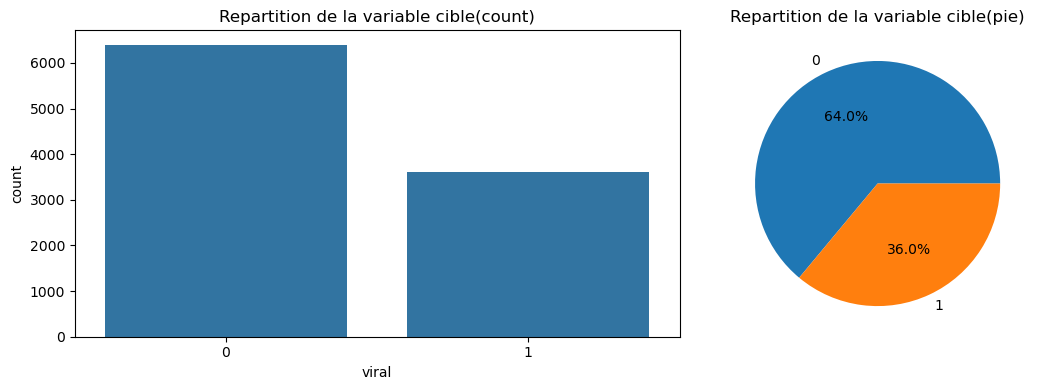

In [15]:
target = pd.DataFrame({
    "nbre_tg" : df['viral'].value_counts(),
    "pct_tg" : df['viral'].value_counts(normalize=True)
})
print("Infos viral : ")
print()
print(target)

print()


plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
sns.countplot(x='viral', data=df)
plt.title("Repartition de la variable cible(count)")
plt.tight_layout()

plt.subplot(1,2,2)
plt.pie(x =target['pct_tg'], labels = target.index, autopct='%1.1f%%')

plt.title("Repartition de la variable cible(pie)")
plt.tight_layout()

plt.show()

> **Classes desequilbrées: Influence sur la stratégie de découpage et sur le choix des métriques**

### Corrélation entre variables

In [16]:
hist = df.drop('viral', axis=1)

num_vals = [c for c in hist.select_dtypes("number").columns]
num_vals

['duree_s',
 'dance',
 'energie',
 'valence',
 'tempo_bpm',
 'acoustique',
 'instruments',
 'paroles',
 'live',
 'intensite_db']

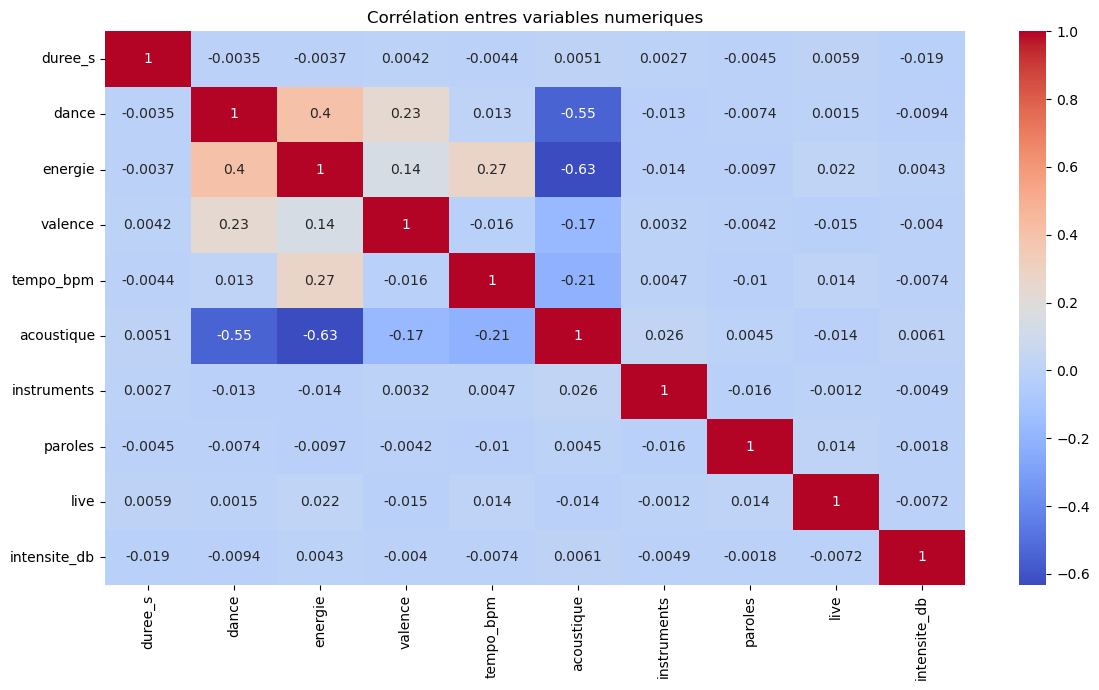

In [17]:
var_corr = hist.corr(numeric_only = True)

plt.figure(figsize=(12,7))

sns.heatmap(var_corr, annot=True, cmap='coolwarm')
plt.title("Corrélation entres variables numeriques")
plt.tight_layout()

plt.show()

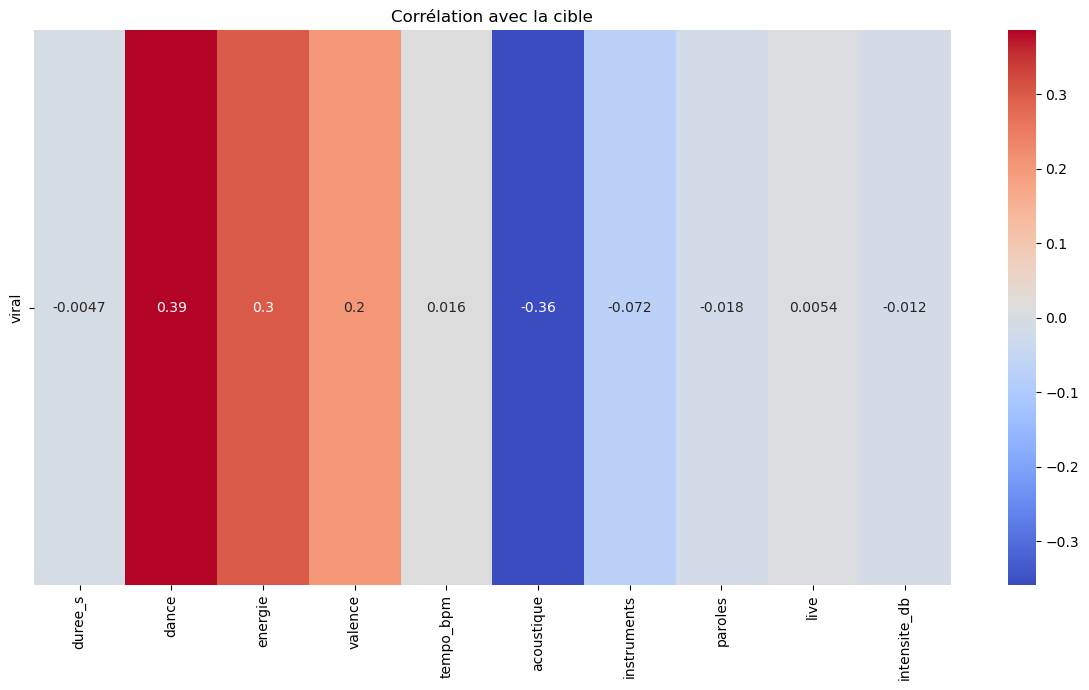

In [18]:
corr = df.corr(numeric_only=True)['viral'].drop('viral')

plt.figure(figsize=(12,7))

sns.heatmap(corr.to_frame().T, annot=True, cmap='coolwarm') # .T pour la variante verticale
plt.title("Corrélation avec la cible")
plt.tight_layout()

plt.show()

### Histogrammes

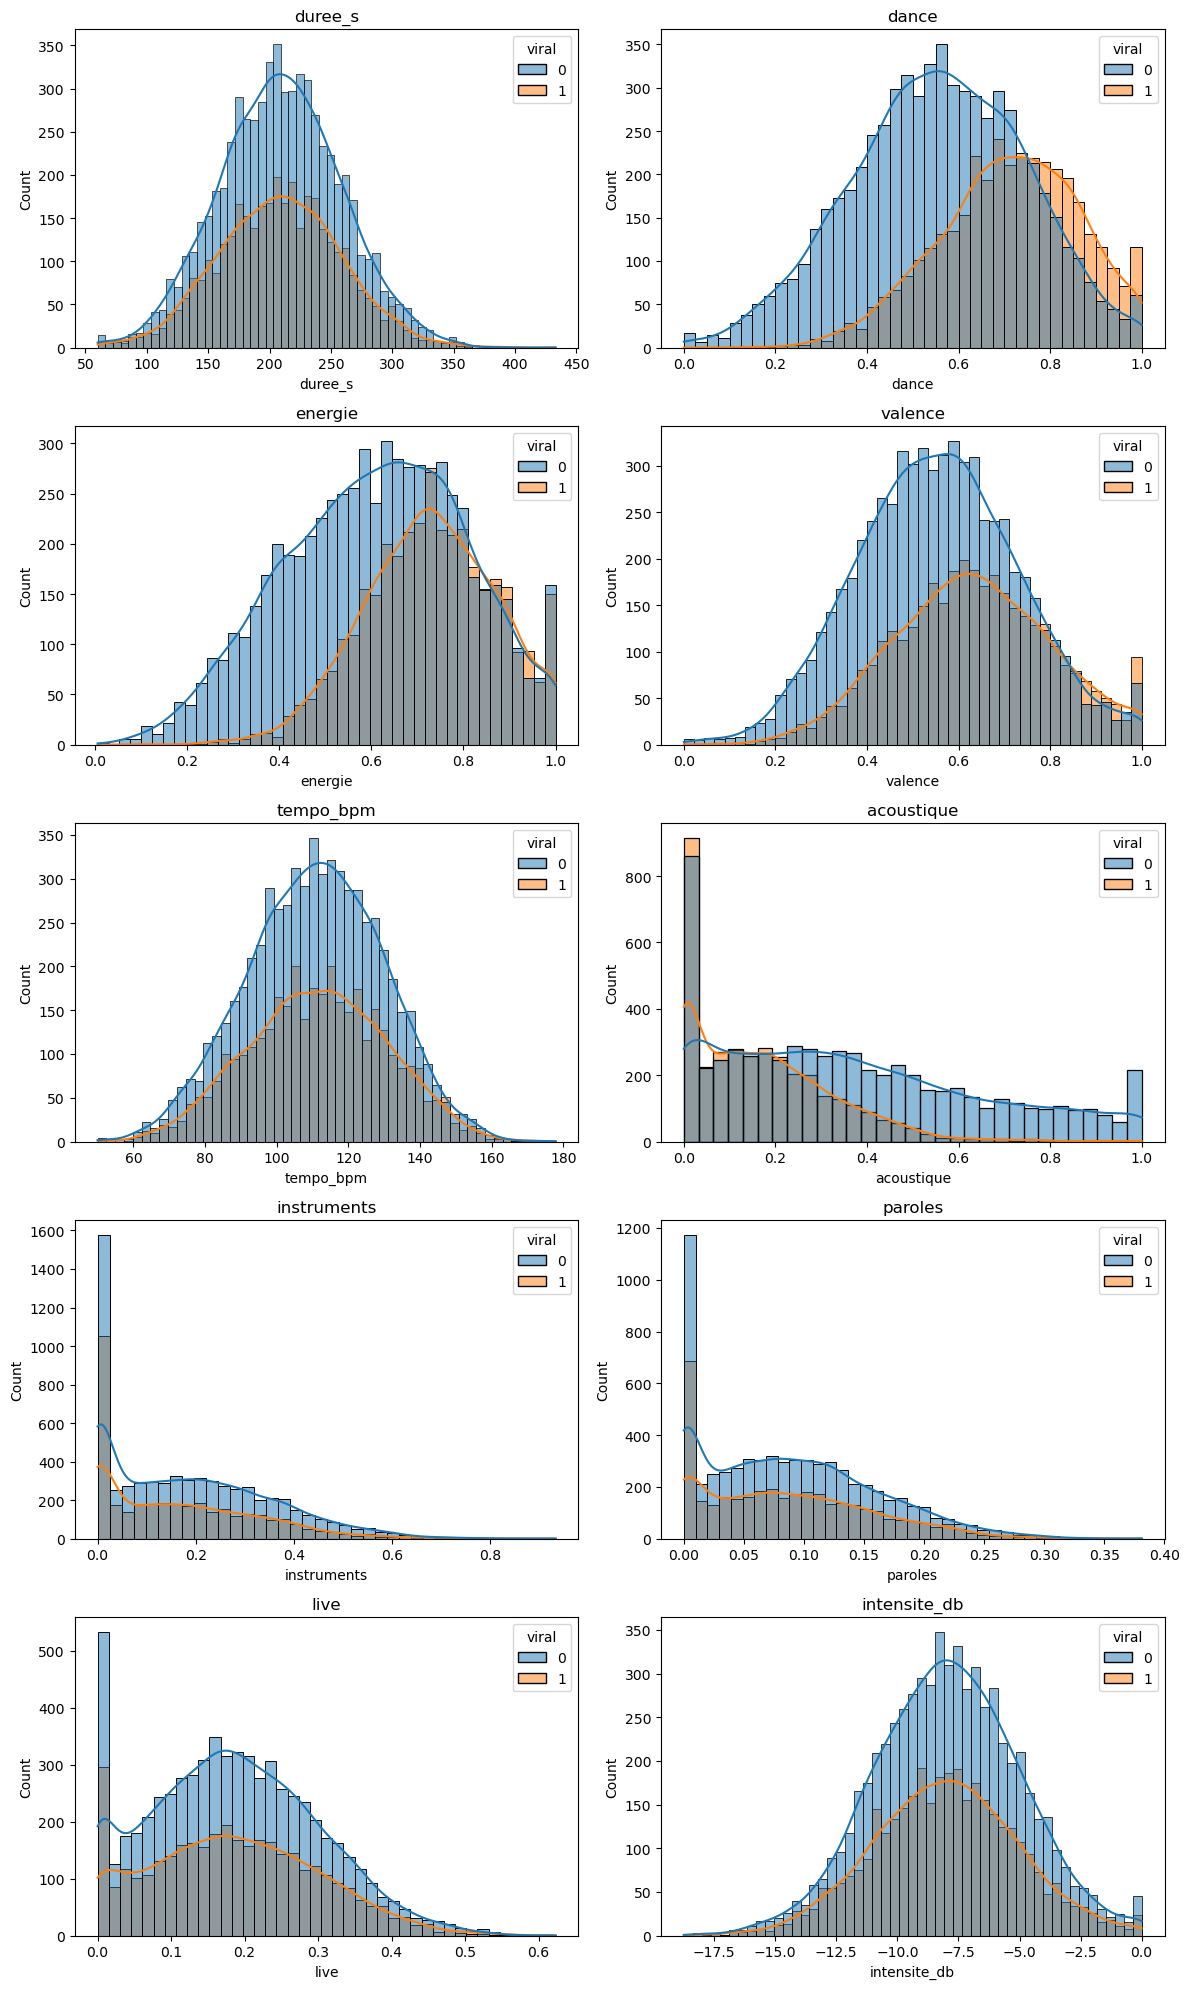

In [19]:
plt.figure(figsize=(12, 20))

for i, col in enumerate(num_vals):
    plt.subplot(5, 2, i+1)
    sns.histplot(x=col, data=df, hue='viral', kde=True)
    plt.title(col)
    
plt.tight_layout()    
plt.show()

### Boxplots

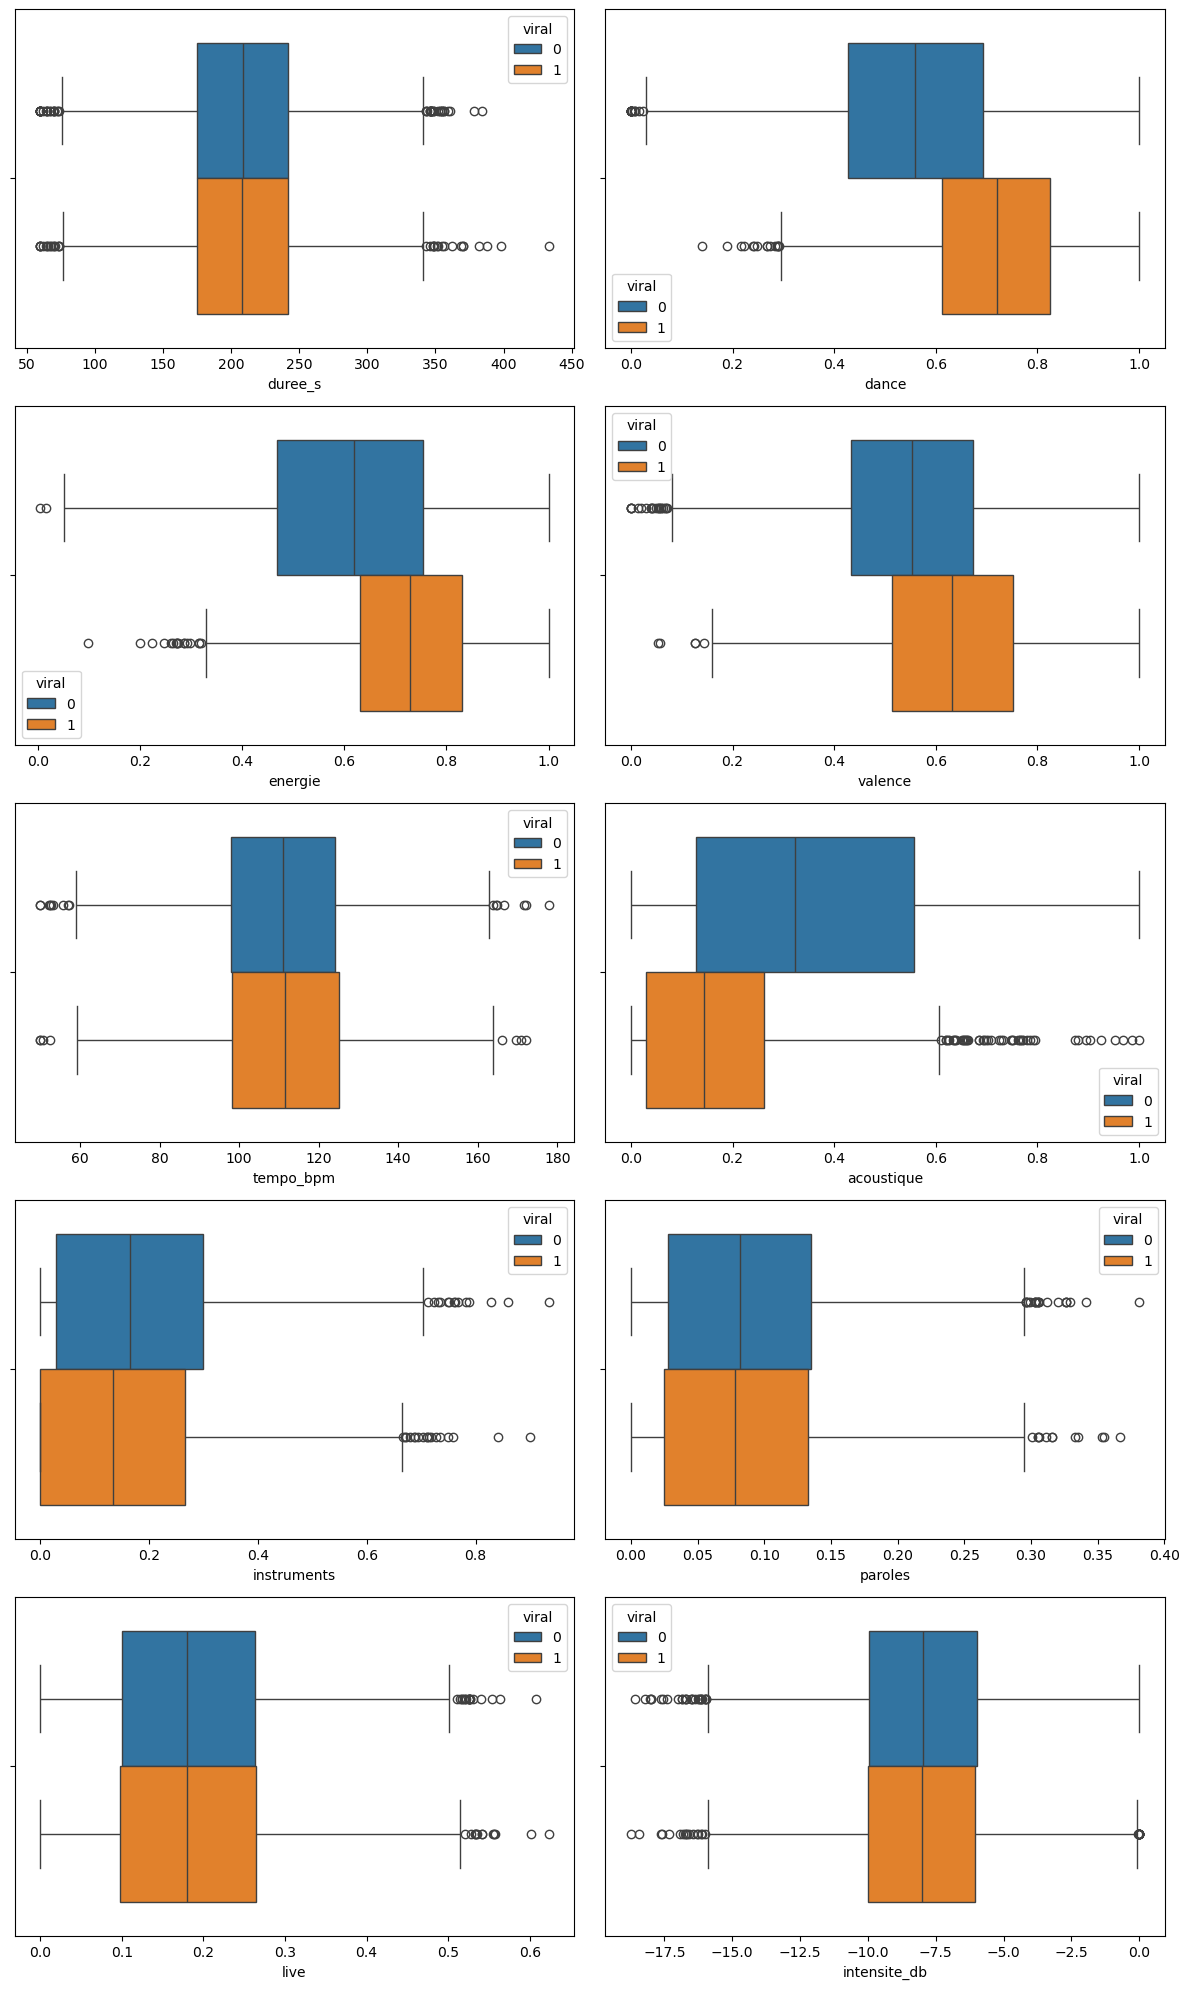

In [20]:
plt.figure(figsize=(12, 20))

for i, col in enumerate(num_vals):
    plt.subplot(5, 2, i+1)
    sns.boxplot(x=col, data=df, hue='viral')
    #plt.title(col)
    
plt.tight_layout()    
plt.show()

# Separation X/y

In [21]:
X = df.drop('viral', axis=1)
y = df['viral']

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                 stratify=y,
                                                 test_size=0.2,
                                                 random_state=SEED)
print(f"Echantillon train : {len(X_train)} | Echantillon test : {len(X_test)}")
print(pd.Series(y_train).value_counts(normalize=True))
print(pd.Series(y_test).value_counts(normalize=True))

Echantillon train : 8000 | Echantillon test : 2000
viral
0    0.6395
1    0.3605
Name: proportion, dtype: float64
viral
0    0.6395
1    0.3605
Name: proportion, dtype: float64


# Pretraitement

In [23]:
numeric_cols = ['duree_s', 'dance', 'energie', 'valence', 'tempo_bpm',
               'acoustique','instruments', 'paroles', 'live', 'intensite_db']

numeric_pipe = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])


preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_pipe, numeric_cols),
    ],
    remainder = 'drop'
)

preprocessor

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['duree_s', 'dance', 'energie', 'valence',
                                  'tempo_bpm', 'acoustique', 'instruments',
                                  'paroles', 'live', 'intensite_db'])])

### Fonction d'appel prep + model

In [24]:
def make_pipe(model) :
    """Assemblage pretraitement + modele"""
    return Pipeline([('prep', preprocessor), ('model', model)])

### Dictionnaire des metriques choisies

In [25]:
SCORING = {
    'precision' : 'precision',
    'recall' : 'recall',
    'f1' : 'f1'
}

# TRAVAIL SUR LA LOGISTIC REGRESSION

### Vue sur les paramteres du modele

In [26]:
LogisticRegression().get_params()

{'C': 1.0,
 'class_weight': None,
 'dual': False,
 'fit_intercept': True,
 'intercept_scaling': 1,
 'l1_ratio': None,
 'max_iter': 100,
 'multi_class': 'deprecated',
 'n_jobs': None,
 'penalty': 'l2',
 'random_state': None,
 'solver': 'lbfgs',
 'tol': 0.0001,
 'verbose': 0,
 'warm_start': False}

### Appel de la fonction make_pipe

In [27]:
pipe_logreg = make_pipe(LogisticRegression(max_iter=1000, class_weight='balanced'))

## Validation croisée

In [28]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

In [29]:
scores = cross_validate(
    pipe_logreg,
    X_train, y_train,
    cv = cv,
    scoring = SCORING,
)

In [30]:
print(f"Clés de scores : {scores.keys()}")

Clés de scores : dict_keys(['fit_time', 'score_time', 'test_precision', 'test_recall', 'test_f1'])


In [31]:
pd.DataFrame(scores)

,fit_time,score_time,test_precision,test_recall,test_f1
0,0.049046,0.040078,0.567931,0.805556,0.666188
1,0.047147,0.037707,0.567423,0.736568,0.641026
2,0.048265,0.036107,0.544135,0.779896,0.641026
3,0.041137,0.032978,0.544304,0.745234,0.629115
4,0.056045,0.035637,0.564070,0.778163,0.654042


In [32]:
for metrics, values in scores.items() : 
    if metrics.startswith('test_') :
        print(f"{metrics} : {values.mean()}")

test_precision : 0.5575728532025046
test_recall : 0.7690833814750626
test_f1 : 0.6462792917248594


### Grille de recherche

**Hyperparametres** :
> C : inverse de la force de regulation : un petit C contraint davantage le modele (limite le surapprentissage), un grand C le laisse plus libre. On regle aussi la strategie d’imputation du pretraitement. Ici : 5 valeurs de C × 2 strategies = 10 combinaisons, chacune sur 5 plis, soit 50 entranements.

In [33]:
param_grid = {
    'model__C' : [0.01, 0.1, 1, 10, 100],
    "prep__num__imputer__strategy": ["median", "mean"],
}

In [34]:
grid = GridSearchCV(
    estimator=pipe_logreg,
    param_grid=param_grid,
    cv=cv,
    scoring=SCORING,
    refit = 'recall', # Metrique d'evaluarion finale
    n_jobs=-1 # Utilisation de tous les coeurs du processeur
)

### Entrainement sur le train

In [35]:
grid.fit(X_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('prep',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['duree_s',
                                                                          'dance',
                                                                          'energie',
                                                                          'valence',
                                                                          'tempo_bpm',
                                                                          'acoustique',
                                                                          'instruments',
                                                                          'paroles',
                                                                          'live',
                                                                          'intensite_db'])])),
                                       ('model',
                                        LogisticRegression(class_weight='balanced',
                                                           max_iter=1000))]),
             n_jobs=-1,
             param_grid={'model__C': [0.01, 0.1, 1, 10, 100],
                         'prep__num__imputer__strategy': ['median', 'mean']},
             refit='recall',
             scoring={'f1': 'f1', 'precision': 'precision', 'recall': 'recall'})

In [36]:
print(f"Meilleur sccore : {grid.best_score_}")
print(f"Meilleures parametres : {grid.best_params_}")

Meilleur sccore : 0.7718569468515308
Meilleures parametres : {'model__C': 0.01, 'prep__num__imputer__strategy': 'median'}


In [37]:
model = grid.best_estimator_

In [38]:
y_pred = model.predict(X_test)

### Classification_report

In [39]:
print(classification_report(y_test, y_pred, target_names=['Non_Viral', 'Viral']))

              precision    recall  f1-score   support

   Non_Viral       0.83      0.67      0.74      1279
       Viral       0.56      0.76      0.64       721

    accuracy                           0.70      2000
   macro avg       0.70      0.71      0.69      2000
weighted avg       0.73      0.70      0.70      2000



### Matrice de confusion

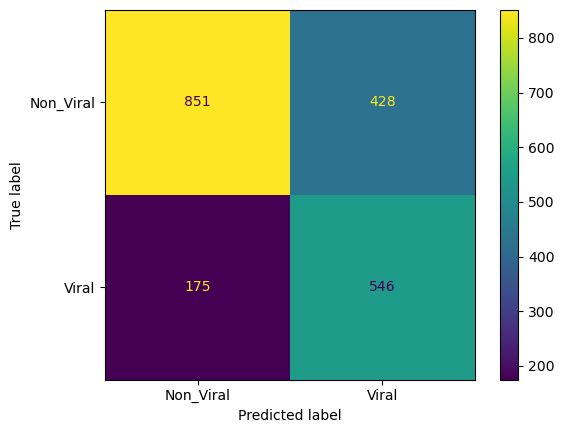

In [40]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred,
                                       display_labels=['Non_Viral', 'Viral'])

### Conclusion

|Mesures|class_weight='balanced'|class_weight='None'|
|---|---|---|
|**precision**|0.83 / 0.56|0.76 / 0.62|
|**recall**|0.67 / 0.76|0.82 / 0.53|
|**f1**|0.74 / 0.64|0.79 / 0.57|
|**Meilleur Score**|0.77|0.51|

#### **NB** : 

> En optimisant le rappel sur une **class_weigt='balanced'** on **detecte mieux les chansons viral** passant de **330 à 546** ce qui induit quand meme une **perte** sur le **target 0 "Non Viral"** pasant de **1050 à 851**.